**PART A – Start with the Data**

Create your project workspace

In [1]:
# CELL 1 — PROJECT WORKSPACE

from pathlib import Path

BASE_DIR = Path("/content/week3_project")

RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project workspace created!")
print("Base directory:", BASE_DIR)
print("Raw directory:", RAW_DIR)
print("Processed directory:", PROCESSED_DIR)

Project workspace created!
Base directory: /content/week3_project
Raw directory: /content/week3_project/data/raw
Processed directory: /content/week3_project/data/processed


Upload your dataset into Colab

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import zipfile

zip_path = "/content/drive/MyDrive/archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(RAW_DIR)

print("RDD2022 extraction completed!")

RDD2022 extraction completed!


Ingest and inspect your data

In [4]:
# Inspect folder structure

for path in list(RAW_DIR.rglob("*"))[:50]:
    print(path.relative_to(RAW_DIR))

RDD_SPLIT
RDD_SPLIT/train
RDD_SPLIT/val
RDD_SPLIT/test
RDD_SPLIT/train/images
RDD_SPLIT/train/labels
RDD_SPLIT/val/images
RDD_SPLIT/val/labels
RDD_SPLIT/test/images
RDD_SPLIT/test/labels
RDD_SPLIT/test/images/Japan_009174.jpg
RDD_SPLIT/test/images/Japan_009942.jpg
RDD_SPLIT/test/images/Norway_004112.jpg
RDD_SPLIT/test/images/Japan_008925.jpg
RDD_SPLIT/test/images/Norway_002385.jpg
RDD_SPLIT/test/images/United_States_000530.jpg
RDD_SPLIT/test/images/United_States_001836.jpg
RDD_SPLIT/test/images/United_States_002726.jpg
RDD_SPLIT/test/images/China_Drone_001148.jpg
RDD_SPLIT/test/images/Japan_004165.jpg
RDD_SPLIT/test/images/India_001722.jpg
RDD_SPLIT/test/images/Norway_002397.jpg
RDD_SPLIT/test/images/India_008376.jpg
RDD_SPLIT/test/images/India_007253.jpg
RDD_SPLIT/test/images/Czech_000141.jpg
RDD_SPLIT/test/images/Norway_005550.jpg
RDD_SPLIT/test/images/India_004675.jpg
RDD_SPLIT/test/images/India_001789.jpg
RDD_SPLIT/test/images/Japan_010998.jpg
RDD_SPLIT/test/images/Norway_005756.jp

In [5]:
from collections import Counter

extensions = Counter(
    p.suffix.lower()
    for p in RAW_DIR.rglob("*")
    if p.is_file()
)

print("File types found:")
print(extensions)

File types found:
Counter({'.jpg': 38385, '.txt': 38385})


In [6]:
image_files = sorted(
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print("Total images found:", len(image_files))

for image in image_files[:2]:
    print(image)

Total images found: 38385
/content/week3_project/data/raw/RDD_SPLIT/test/images/China_Drone_000008.jpg
/content/week3_project/data/raw/RDD_SPLIT/test/images/China_Drone_000017.jpg


Filename: China_Drone_000008.jpg
Image size: (512, 512)
Image mode: RGB


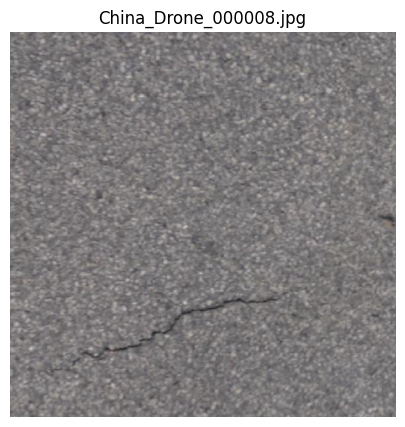

Filename: China_Drone_000017.jpg
Image size: (512, 512)
Image mode: RGB


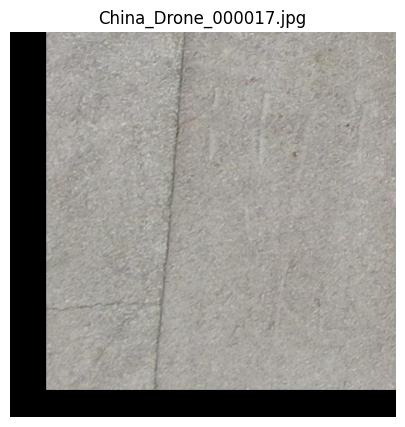

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

for image_path in image_files[:2]:

    image = Image.open(image_path)

    print("Filename:", image_path.name)
    print("Image size:", image.size)
    print("Image mode:", image.mode)

    plt.figure(figsize=(7, 5))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

**PART B – Prepare the Data**

In [8]:
!pip install -q pillow pandas matplotlib

In [9]:
from PIL import Image, UnidentifiedImageError
import pandas as pd
import hashlib
import json
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:

from PIL import Image, UnidentifiedImageError
from pathlib import Path
import pandas as pd
import hashlib

# Configuration
MAX_IMAGES = 100
CONVERT_TO_RGB = True

# Find images
image_files = sorted(
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print("Total images available:", len(image_files))

assert len(image_files) > 0, "No images found!"

# Select only the first 100 images
selected_images = image_files[:MAX_IMAGES]

print("Images selected:", len(selected_images))

# Output directory
image_dir = PROCESSED_DIR / "images"
image_dir.mkdir(parents=True, exist_ok=True)

rows = []
failed_files = []

for f in selected_images:
    try:
        with Image.open(f) as im:
            im.load()

            original_size = im.size
            original_mode = im.mode

            transformed = im.convert("RGB") if CONVERT_TO_RGB else im.copy()

            # Save prepared image
            target = image_dir / f"{f.stem}.png"
            transformed.save(target, format="PNG")

            rows.append({
                "source": str(f.relative_to(RAW_DIR)),
                "source_sha256": hashlib.sha256(
                    f.read_bytes()
                ).hexdigest(),
                "original_width": original_size[0],
                "original_height": original_size[1],
                "original_mode": original_mode,
                "output": str(target.relative_to(BASE_DIR)),
                "output_width": transformed.width,
                "output_height": transformed.height,
                "processing": "RGB conversion; original dimensions preserved"
            })

    except (UnidentifiedImageError, OSError) as err:
        failed_files.append({
            "file": str(f),
            "error": str(err)
        })

# Export manifest
prepared_path = PROCESSED_DIR / "image_manifest.csv"

pd.DataFrame(rows).to_csv(
    prepared_path,
    index=False
)

print("\n--- PREPARATION RESULTS ---")
print("Selected images:", len(selected_images))
print("Successfully processed:", len(rows))
print("Failed images:", len(failed_files))
print("Manifest:", prepared_path)
print("Preparation completed!")


Total images available: 38385
Images selected: 100

--- PREPARATION RESULTS ---
Selected images: 100
Successfully processed: 100
Failed images: 0
Manifest: /content/week3_project/data/processed/image_manifest.csv
Preparation completed!


In [13]:
assert prepared_path.exists()
assert prepared_path.stat().st_size > 0
assert len(rows) > 0

manifest_df = pd.read_csv(prepared_path)

assert len(manifest_df) == len(rows)

print("Image preparation validation: PASS")
print("Prepared images:", len(rows))
print("Failed images:", len(failed_files))

display(manifest_df.head())

Image preparation validation: PASS
Prepared images: 100
Failed images: 0


,source,source_sha256,original_width,original_height,original_mode,output,output_width,output_height,processing
0,RDD_SPLIT/test/images/China_Drone_000008.jpg,a9754681705e659d7ba568ce813d40029bf4bb8cdd24bc...,512,512,RGB,data/processed/images/China_Drone_000008.png,512,512,RGB conversion; original dimensions preserved
1,RDD_SPLIT/test/images/China_Drone_000017.jpg,2abb3934ce63517a0c90e5da2d70c1ffad6d057dafca6b...,512,512,RGB,data/processed/images/China_Drone_000017.png,512,512,RGB conversion; original dimensions preserved
2,RDD_SPLIT/test/images/China_Drone_000040.jpg,2d09975652374884727a4aceeb31d7ce30582bea018aff...,512,512,RGB,data/processed/images/China_Drone_000040.png,512,512,RGB conversion; original dimensions preserved
3,RDD_SPLIT/test/images/China_Drone_000052.jpg,143b125b044fc4fa7b74b75ef7ee13bece7e4a3d9c72cf...,512,512,RGB,data/processed/images/China_Drone_000052.png,512,512,RGB conversion; original dimensions preserved
4,RDD_SPLIT/test/images/China_Drone_000053.jpg,7a270d307107af848932e8402db818e884754b0c7bdd5e...,512,512,RGB,data/processed/images/China_Drone_000053.png,512,512,RGB conversion; original dimensions preserved


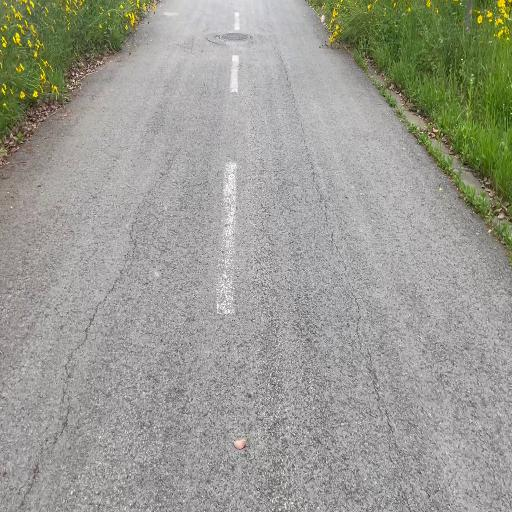

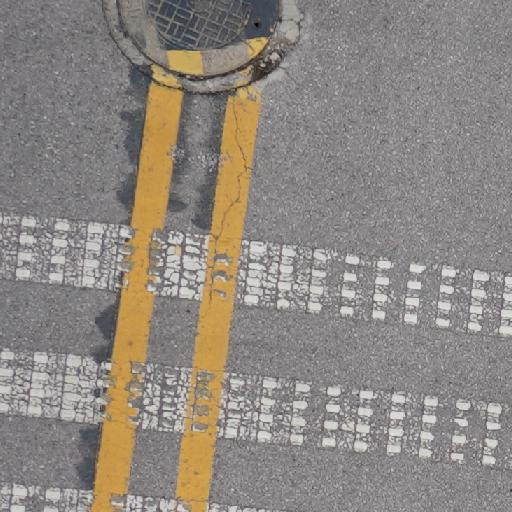

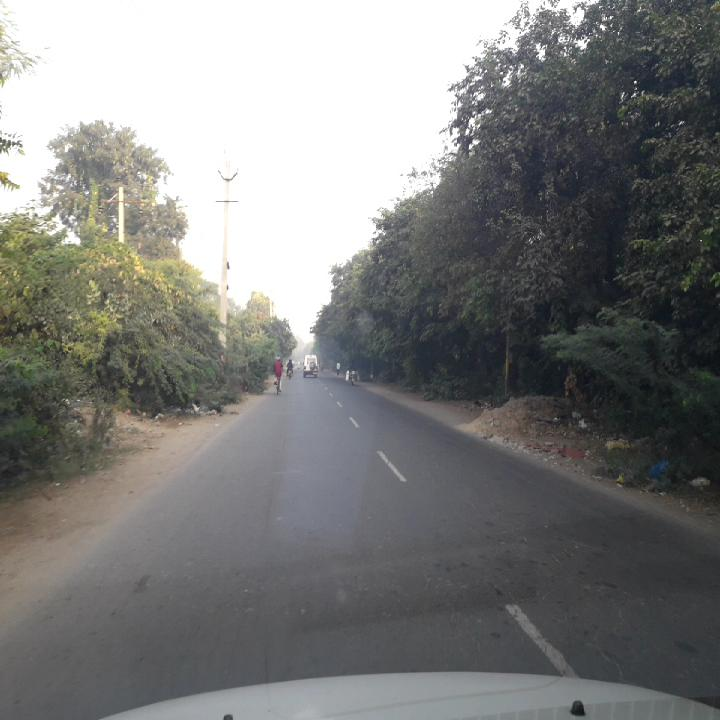

In [14]:
from IPython.display import display

for image_path in list(image_dir.glob("*.png"))[:3]:

    display(Image.open(image_path))

In [15]:
lineage_entries = []

for row in rows:

    lineage_entries.append({
        "source": row["source"],
        "source_sha256": row["source_sha256"],
        "prepared_output": row["output"],
        "processing": row["processing"]
    })

In [16]:
from datetime import datetime, timezone

manifest = {
    "pipeline_version": "week3-v1",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "dataset": "RDD2022",
    "records": lineage_entries
}

manifest_path = BASE_DIR / "data" / "week3_manifest.json"

manifest_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

print("Lineage manifest created!")
print(manifest_path)

Lineage manifest created!
/content/week3_project/data/week3_manifest.json


In [17]:
with open(manifest_path, "r") as f:
    saved_manifest = json.load(f)

assert len(saved_manifest["records"]) == len(rows)

print("Lineage verification: PASS")
print("Registered records:", len(saved_manifest["records"]))

Lineage verification: PASS
Registered records: 100


**Part C — Build and Document V1 Data Pipeline**

In [18]:
from pathlib import Path

BASE_DIR = Path("/content/week3_project")
PROCESSED_DIR = BASE_DIR / "data" / "processed"

IMAGE_DIR = PROCESSED_DIR / "images"
IMAGE_MANIFEST = PROCESSED_DIR / "image_manifest.csv"

print("Prepared image folder exists:", IMAGE_DIR.exists())
print("Image manifest exists:", IMAGE_MANIFEST.exists())

if IMAGE_DIR.exists():
    prepared_images = list(IMAGE_DIR.glob("*.png"))
    print("Number of prepared images:", len(prepared_images))

Prepared image folder exists: True
Image manifest exists: True
Number of prepared images: 3414


In [19]:
from pathlib import Path

RAW_DIR = Path("/content/week3_project/data/raw")

print("Folders inside RAW_DIR:")
for item in RAW_DIR.iterdir():
    if item.is_dir():
        print(item.name)

Folders inside RAW_DIR:
RDD_SPLIT


In [23]:
from pathlib import Path
import shutil

SOURCE_IMAGE_FOLDER = Path(
    "/content/week3_project/data/raw/RDD_SPLIT"
)

PART_C_SOURCE = RAW_DIR / "rdd2022_partc_sample"
PART_C_SOURCE.mkdir(parents=True, exist_ok=True)

MAX_IMAGES = 20

image_files = sorted([
    p for p in SOURCE_IMAGE_FOLDER.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:MAX_IMAGES]

assert image_files, "No images found. Check SOURCE_IMAGE_FOLDER."

for index, src in enumerate(image_files, start=1):
    target = PART_C_SOURCE / f"source_{index:03d}{src.suffix.lower()}"
    shutil.copy2(src, target)

print("Images copied:", len(image_files))
print("Part C source folder:", PART_C_SOURCE)

Images copied: 20
Part C source folder: /content/week3_project/data/raw/rdd2022_partc_sample


In [24]:
print("Images available for Part C:")

for image in sorted(PART_C_SOURCE.iterdir()):
    print(image.name)

Images available for Part C:
source_001.jpg
source_002.jpg
source_003.jpg
source_004.jpg
source_005.jpg
source_006.jpg
source_007.jpg
source_008.jpg
source_009.jpg
source_010.jpg
source_011.jpg
source_012.jpg
source_013.jpg
source_014.jpg
source_015.jpg
source_016.jpg
source_017.jpg
source_018.jpg
source_019.jpg
source_020.jpg


In [25]:

# ============================================================
# CELL 7 — REQUIRED: COMMON V1 PIPELINE UTILITIES
# AI-Based Road Damage Detection and Visualisation System
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

# STEP 1: Define standard project paths

BASE_DIR = Path("/content/week3_project")

RAW_DIR = BASE_DIR / "data" / "raw"

PIPE_DIR = BASE_DIR / "data" / "pipeline_v1"

# Create pipeline output directory
PIPE_DIR.mkdir(parents=True, exist_ok=True)

# Store registered pipeline runs for repeatability verification
PIPELINE_RUNS = {}


# STEP 2: Calculate SHA-256 checksum

def sha256_file(path):

    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


# STEP 3: Resolve an explicitly selected source

def resolve_source(relative_path, folder=False):

    source = RAW_DIR / relative_path

    if folder:

        if not source.is_dir():
            raise FileNotFoundError(
                f"Source folder not found: {source}"
            )

    else:

        if not source.is_file():
            raise FileNotFoundError(
                f"Source file not found: {source}"
            )

    return source


# STEP 4: Execute the selected V1 data pipeline

def execute_pipeline(
    kind,
    source,
    inspect_fn,
    prepare_fn,
    configuration
):

    source = Path(source)

    # INGEST: Identify relevant source files
    if kind == "images":

        inputs = sorted(
            p for p in source.iterdir()
            if p.is_file()
            and p.suffix.lower() in {
                ".png", ".jpg", ".jpeg", ".webp"
            }
        )

    else:

        inputs = [source]

    if not inputs or any(not p.is_file() for p in inputs):

        raise ValueError(
            "No valid source files to ingest."
        )

    # INSPECT: Apply data-type-specific inspection
    inspection = inspect_fn(inputs, configuration)

    # Define output directory
    output_dir = PIPE_DIR / kind
    output_dir.mkdir(parents=True, exist_ok=True)

    # PREPARE / STORE: Apply selected transformation
    outputs, mappings, method = prepare_fn(
        inputs,
        output_dir,
        configuration
    )

    outputs = [Path(p) for p in outputs]

    # VALIDATE: Check prepared outputs
    if not outputs:

        raise ValueError(
            "No prepared outputs were produced."
        )

    for output in outputs:

        if not output.is_file():

            raise FileNotFoundError(
                f"Prepared output missing: {output}"
            )

        if output.stat().st_size == 0:

            raise ValueError(
                f"Prepared output is empty: {output}"
            )

    # Record basic validation evidence
    validation = {

        "output_count": len(outputs),

        "output_sha256": [
            sha256_file(p) for p in outputs
        ],

        "output_bytes": [
            p.stat().st_size for p in outputs
        ]
    }

    # RECORD LINEAGE: Create pipeline execution record
    record = {

        "pipeline_version": "week3-v1",

        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "data_type": kind,

        "configuration": configuration,

        "processing_method": method,

        "sources": [
            {
                "path": str(p),
                "sha256": sha256_file(p)
            }
            for p in inputs
        ],

        "outputs": [
            str(p) for p in outputs
        ],

        "source_output_mapping": mappings,

        "inspection": inspection,

        "validation": validation,

        "source_version": "Not verified",

        "access_rights": (
            "Not verified — check before sharing"
        )
    }

    # Save pipeline manifest
    manifest_path = output_dir / "pipeline_manifest.json"

    manifest_path.write_text(
        json.dumps(
            record,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print(
        f"SUCCESS: {kind} | "
        f"Inputs: {len(inputs)} | "
        f"Outputs: {len(outputs)}"
    )

    print("Manifest:", manifest_path)

    return record


# STEP 5: Register and run a selected pathway

def register_and_run(
    kind,
    source,
    inspect_fn,
    prepare_fn,
    configuration
):

    # Keep the runner for repeatability verification
    def runner():

        return execute_pipeline(
            kind,
            source,
            inspect_fn,
            prepare_fn,
            configuration
        )

    first = runner()

    PIPELINE_RUNS[kind] = {

        "first": first,

        "runner": runner
    }

    return first


# STEP 6: Confirm Cell 7 is ready

print("Cell 7 ready.")

print("Run ONLY the selected Cell 8 pathway(s).")

print("Common pipeline utilities are available.")


Cell 7 ready.
Run ONLY the selected Cell 8 pathway(s).
Common pipeline utilities are available.


In [26]:

# CELL 8C — COMPUTER VISION / IMAGE PIPELINE

from PIL import Image

# STEP 1: Select the actual source folder
SOURCE_C = resolve_source(
    "rdd2022_partc_sample",
    folder=True
)

# STEP 2: Use the preparation decision selected in Part B
CONFIG_C = {
    "resize": None,
    "convert_rgb": True
}

# STEP 3: Inspect source images
def inspect_images(inputs, cfg):

    properties = []

    for src in inputs:

        # Check whether the image can be opened
        with Image.open(src) as im:
            im.verify()

        # Reopen to inspect image properties
        with Image.open(src) as im:

            properties.append({
                "name": src.name,
                "size": list(im.size),
                "mode": im.mode
            })

    return {
        "image_count": len(inputs),
        "sample": properties[:3]
    }


# STEP 4: Prepare images
def prepare_images(inputs, out, cfg):

    outputs = []
    mapping = []

    image_size = cfg["resize"]
    convert_rgb = cfg["convert_rgb"]

    for i, src in enumerate(inputs, 1):

        with Image.open(src) as im:

            # Convert image to RGB
            if convert_rgb:
                image = im.convert("RGB")
            else:
                image = im.copy()

            # Resize only if selected
            if image_size is not None:
                image = image.resize(tuple(image_size))

            # Save prepared image
            target = out / f"prepared_{i:03d}.png"
            image.save(target, format="PNG")

        outputs.append(target)

        # Record source-to-output relationship
        mapping.append({
            "source": str(src),
            "output": str(target)
        })

    processing_method = (
        f"convert_rgb={convert_rgb}; "
        f"resize={image_size}"
    )

    return outputs, mapping, processing_method


# STEP 5: Execute and register the pipeline
run_C = register_and_run(
    "images",
    SOURCE_C,
    inspect_images,
    prepare_images,
    CONFIG_C
)

print("Cell 8C completed successfully.")
print("Inspection:", run_C["inspection"])


SUCCESS: images | Inputs: 20 | Outputs: 20
Manifest: /content/week3_project/data/pipeline_v1/images/pipeline_manifest.json
Cell 8C completed successfully.
Inspection: {'image_count': 20, 'sample': [{'name': 'source_001.jpg', 'size': [512, 512], 'mode': 'RGB'}, {'name': 'source_002.jpg', 'size': [512, 512], 'mode': 'RGB'}, {'name': 'source_003.jpg', 'size': [512, 512], 'mode': 'RGB'}]}


In [27]:

# CELL 9 — REPEATABILITY AND PROVENANCE VERIFICATION

# STEP 1: Confirm that a pipeline has been registered
assert PIPELINE_RUNS, (
    "No pipeline runs registered. "
    "Run Cell 8C first."
)

print("--- Repeatability Verification ---")

# STEP 2: Rerun each selected pipeline
for kind, entry in PIPELINE_RUNS.items():

    first = entry["first"]

    # Execute the same pipeline again
    second = entry["runner"]()

    # STEP 3: Verify source fingerprints
    assert first["sources"] == second["sources"], (
        f"Source fingerprint changed for {kind}"
    )

    # STEP 4: Verify prepared output fingerprints
    assert first["validation"] == second["validation"], (
        f"Prepared output changed for {kind}"
    )

    # STEP 5: Verify source-to-output mapping
    assert (
        first["source_output_mapping"]
        == second["source_output_mapping"]
    ), (
        f"Source-to-output mapping changed for {kind}"
    )

    print(
        f"PASS: {kind} — source fingerprints, "
        "prepared outputs and mappings match"
    )

# STEP 6: Final verification
print("\nAll selected pipelines passed repeatability smoke checks.")


--- Repeatability Verification ---
SUCCESS: images | Inputs: 20 | Outputs: 20
Manifest: /content/week3_project/data/pipeline_v1/images/pipeline_manifest.json
PASS: images — source fingerprints, prepared outputs and mappings match

All selected pipelines passed repeatability smoke checks.


Total prepared images: 20
prepared_001.png | Dimensions: (512, 512) | Mode: RGB


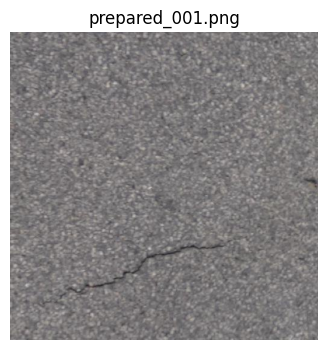

prepared_002.png | Dimensions: (512, 512) | Mode: RGB


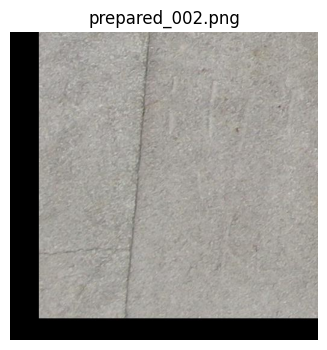

prepared_003.png | Dimensions: (512, 512) | Mode: RGB


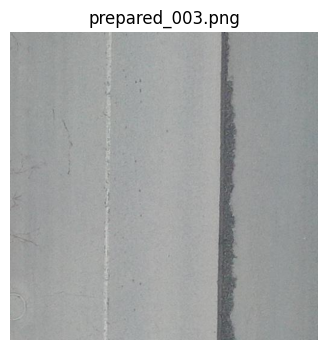

In [28]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

OUTPUT_DIR = (
    Path("/content/week3_project/data/pipeline_v1/images")
)

prepared_images = sorted(OUTPUT_DIR.glob("prepared_*.png"))

print("Total prepared images:", len(prepared_images))

assert len(prepared_images) > 0

# Display the first three prepared images
for image_path in prepared_images[:3]:

    with Image.open(image_path) as img:
        print(
            image_path.name,
            "| Dimensions:", img.size,
            "| Mode:", img.mode
        )

        plt.figure(figsize=(8, 4))
        plt.imshow(img)
        plt.title(image_path.name)
        plt.axis("off")
        plt.show()